In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import torch
import torch.nn as nn 
import torch.functional as F
from torch.utils.data import DataLoader,TensorDataset

In [2]:
raw_x,raw_y = load_iris(return_X_y=True)

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
device

device(type='cuda')

In [5]:
std_x = StandardScaler().fit_transform(raw_x)

In [6]:
X_train,X_test,y_train,y_test = train_test_split(std_x,raw_y,stratify=raw_y,shuffle=True)

In [7]:
X_train = torch.tensor(X_train,dtype=torch.float32,device=device)
X_test = torch.tensor(X_test,dtype=torch.float32,device=device)
y_train = torch.tensor(y_train,dtype=torch.float32,device=device)
y_test = torch.tensor(y_test,dtype=torch.float32,device=device)

In [8]:
X_train

tensor([[ 7.9567e-01, -5.9237e-01,  4.7857e-01,  3.9577e-01],
        [ 1.0380e+00,  9.8217e-02,  5.3541e-01,  3.9577e-01],
        [-4.1601e-01,  1.0190e+00, -1.3971e+00, -1.3154e+00],
        [ 1.1592e+00, -5.9237e-01,  5.9225e-01,  2.6414e-01],
        [-1.1430e+00, -1.3198e-01, -1.3402e+00, -1.3154e+00],
        [ 1.8983e-01, -1.9736e+00,  7.0592e-01,  3.9577e-01],
        [ 5.5333e-01, -1.7434e+00,  3.6490e-01,  1.3251e-01],
        [ 2.2497e+00, -1.3198e-01,  1.3311e+00,  1.4488e+00],
        [ 5.5333e-01, -3.6218e-01,  1.0469e+00,  7.9067e-01],
        [-1.0218e+00,  3.2841e-01, -1.4539e+00, -1.3154e+00],
        [-5.2506e-02, -8.2257e-01,  8.0709e-02,  8.7755e-04],
        [-1.0218e+00, -1.7434e+00, -2.6032e-01, -2.6239e-01],
        [-1.5065e+00,  9.8217e-02, -1.2834e+00, -1.3154e+00],
        [ 4.3217e-01, -5.9237e-01,  5.9225e-01,  7.9067e-01],
        [ 2.2497e+00, -1.0528e+00,  1.7858e+00,  1.4488e+00],
        [-9.0068e-01,  1.0190e+00, -1.3402e+00, -1.1838e+00],
        

In [124]:
class MultiClassLogisitcRegression(nn.Module):
    def __init__(self,num_of_features,num_of_layers,num_of_neurons_per_layer,num_of_classes,learning_rate,drop_prop=0.3):
        super().__init__()
        self.num_of_features = num_of_features
        self.num_of_layers = num_of_layers
        self.num_of_neruons_per_layer = num_of_neurons_per_layer
        self.learning_rate = learning_rate
        self.num_of_classes = num_of_classes
        self.net = nn.Sequential()
        self.net.append(nn.Linear(self.num_of_features,num_of_neurons_per_layer))
        self.net.append(nn.LeakyReLU())
        self.net.append(torch.nn.BatchNorm1d(num_of_neurons_per_layer))
        self.net.append(nn.Dropout(drop_prop))
        for layer in range(self.num_of_layers-2):
            self.net.append(nn.Linear(num_of_neurons_per_layer,num_of_neurons_per_layer))
            self.net.append(nn.LeakyReLU())
            self.net.append(torch.nn.BatchNorm1d(num_of_neurons_per_layer))
            self.net.append(nn.Dropout(drop_prop))
        self.net.append(nn.Linear(num_of_neurons_per_layer,num_of_classes))
    def forward(self,X):
        return self.net(X)
    def fit(self,X,y,epochs,num_of_bacthes,optim='AdamW'):
        optims = {'AdamW':torch.optim.AdamW,'SGD':torch.optim.SGD,'Adam':torch.optim.Adam,'AdaDelta':torch.optim.Adadelta}
        loss = nn.CrossEntropyLoss(reduction='mean')
        cost = []
        optimzer =optims[optim](self.net.parameters(),lr=self.learning_rate) #torch.optim.AdamW(self.net.parameters(),lr=self.learning_rate)
        torch.manual_seed(42)
        nn.Module.train(self)
        for e in range(epochs):
            d = DataLoader(TensorDataset(X,y),shuffle=True,batch_size=num_of_bacthes)
            for b_x,b_y in d:
                optimzer.zero_grad()
                b_x=b_x.to(device)
                b_y=b_y.type(torch.LongTensor).to(device)
                net_output = self.net.forward(b_x)
                l = loss(net_output,b_y)
                l.backward()
                cost.append(l.item())
                optimzer.step()
        return cost
    def predict(self,X):
        nn.Module.eval(self)
        with torch.no_grad():
            return torch.argmax(self.forward(X),dim=1)
    def accuracy(self,X,y):
        nn.Module.eval(self)
        with torch.no_grad():
            return (torch.sum(self.predict(X)==y).flatten()/y.size(0)).item()
        

In [125]:
#model = MultiClassLogisitcRegression(X_train.size(1),4,8,3,0.01).to(device)
model = MultiClassLogisitcRegression(X_train.size(1),num_of_layers=2,num_of_neurons_per_layer=8,num_of_classes=y_test.unique().size()[0],learning_rate=0.015).to(device)

In [126]:
y_test.unique().size()

torch.Size([3])

In [127]:
X_train.size(1)

4

In [128]:
losses = model.fit(X_train,y_train,epochs=70,num_of_bacthes=16)

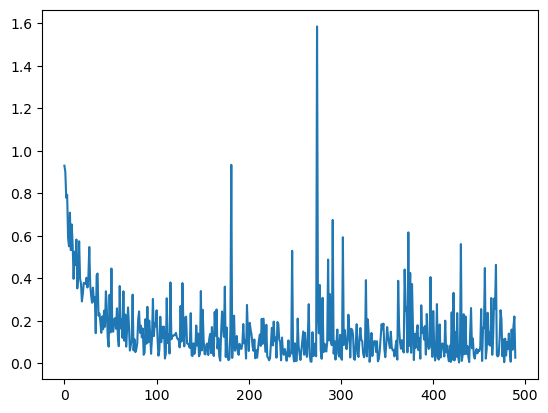

In [129]:
plt.plot(losses)

In [130]:
np.mean(losses)

np.float64(0.15683584459582153)

In [131]:
X_test[model.predict(X_test)!=y_test]

tensor([[ 0.5533, -0.5924,  0.7628,  0.3958]], device='cuda:0')

In [132]:
y_test[model.predict(X_test)!=y_test]

tensor([2.], device='cuda:0')

In [133]:
model.accuracy(X_test,y_test)

0.9736841917037964

In [134]:
np.unique(raw_y)

array([0, 1, 2])

In [135]:
import optuna
from optuna import Trial

In [136]:
def paramater_tuning(trial:Trial):
    dp = trial.suggest_float('prob_drop',0,0.8,step=0.05)
    o = trial.suggest_categorical('optim',['AdamW','SGD','AdaDelta','Adam'])
    num_of_layers = trial.suggest_int('num_of_layers',2,10,step=1)
    num_of_neurons_per_layer=trial.suggest_int('num_of_neurons_per_layer',4,20,step=1)
    learning_rate = trial.suggest_float('learning_rate',0.0001,0.1,step=0.0001)
    model = MultiClassLogisitcRegression(num_of_features=X_test.size(1),num_of_layers=num_of_layers,num_of_classes=3,learning_rate=learning_rate,num_of_neurons_per_layer=num_of_neurons_per_layer,drop_prop=dp).to(device=device)
    model.fit(X_train,y_train,epochs=70,num_of_bacthes=16,optim=o)
    return model.accuracy(X_test,y_test)


In [137]:
study = optuna.create_study(
    study_name='mulitnomilaLogisitcRegression',
    direction='maximize',
    storage='sqlite:///MLR.db',
    load_if_exists=True
)
study.optimize(paramater_tuning,n_trials=80,show_progress_bar=True)

[I 2025-09-30 20:10:14,890] A new study created in RDB with name: mulitnomilaLogisitcRegression


  0%|          | 0/80 [00:00<?, ?it/s]

[I 2025-09-30 20:10:17,614] Trial 0 finished with value: 0.6578947305679321 and parameters: {'prob_drop': 0.35000000000000003, 'optim': 'Adam', 'num_of_layers': 10, 'num_of_neurons_per_layer': 16, 'learning_rate': 0.0902}. Best is trial 0 with value: 0.6578947305679321.
[I 2025-09-30 20:10:19,612] Trial 1 finished with value: 0.5789473652839661 and parameters: {'prob_drop': 0.4, 'optim': 'AdaDelta', 'num_of_layers': 7, 'num_of_neurons_per_layer': 20, 'learning_rate': 0.0144}. Best is trial 0 with value: 0.6578947305679321.
[I 2025-09-30 20:10:20,548] Trial 2 finished with value: 0.9736841917037964 and parameters: {'prob_drop': 0.30000000000000004, 'optim': 'AdamW', 'num_of_layers': 3, 'num_of_neurons_per_layer': 11, 'learning_rate': 0.02}. Best is trial 2 with value: 0.9736841917037964.
[I 2025-09-30 20:10:22,788] Trial 3 finished with value: 0.44736841320991516 and parameters: {'prob_drop': 0.65, 'optim': 'AdaDelta', 'num_of_layers': 8, 'num_of_neurons_per_layer': 15, 'learning_rate':

In [138]:
study.best_params

{'prob_drop': 0.7000000000000001,
 'optim': 'AdamW',
 'num_of_layers': 3,
 'num_of_neurons_per_layer': 18,
 'learning_rate': 0.0112}

In [139]:
optuna.visualization.plot_slice(study)